# Oil Well Region Selection: Profit and Risk Analysis

An oil company needs to decide in which of three regions to develop new wells. For each region, geological exploration data is available for 100,000 sample points: three anonymized features (`f0`, `f1`, `f2`) and the volume of reserves (`product`).

**Approach**

1. Train a Linear Regression model per region to predict the reserve volume of each well.
2. Select the 200 wells with the highest predicted reserves and calculate the resulting profit.
3. Use bootstrapping to estimate the distribution of profit, its 95% confidence interval and the risk of loss for each region.
4. Recommend the region with the highest average profit among those whose risk of loss is below 2.5%.

## Setup

In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.ticker as ticker

## Load Data

In [12]:
data0 = pd.read_csv('./datasets/geo_data_0.csv')
data1 = pd.read_csv('./datasets/geo_data_1.csv')
data2 = pd.read_csv('./datasets/geo_data_2.csv')

## Data Integrity Check

In [13]:
data0.info()
data1.info()
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null 

Each of the three regions has 100,000 rows and no missing values: an identifier (`id`), three numeric features (`f0`, `f1`, `f2`) and the target `product`.

## Business Parameters

| Parameter | Variable | Value |
|---|---|---|
| Total development budget (USD) | `orcamento_total` | 100,000,000 |
| Wells selected for development | `n_pocos` | 200 |
| Wells sampled in each bootstrap iteration | `pocos_amostra` | 500 |
| Revenue per unit of product (USD) | `receita_unidade` | 4,500 |
| Bootstrap iterations | `n_iter` | 1,000 |
| Random seed | `random_state` | 12345 |

In [14]:
orcamento_total = 100000000
n_pocos = 200
pocos_amostra = 500
receita_unidade = 4500
n_iter = 1000
random_state = 12345


## Helper Functions

- `train(data)` — splits a region's data into training (75%) and validation (25%) sets, fits a Linear Regression model and returns the validation targets, the predictions, the mean prediction and the RMSE.
- `calcular_lucro(...)` — selects the `n_pocos` wells with the highest predicted reserves, sums their **actual** reserves, multiplies by the revenue per unit and subtracts the total budget.
- `bootstrap(...)` — draws `n_iter` samples of `pocos_amostra` wells with replacement from the validation set, calculates the profit of each sample and returns the profit distribution.

In [15]:
def train(data):
    target = data['product']
    features = data.drop(['product','id'], axis=1)
    features_train, features_valid, target_train, target_valid = train_test_split(features, target, test_size=0.25, random_state=random_state)

    model = LinearRegression()
    model.fit(features_train, target_train)
    predictions_valid = model.predict(features_valid)

    rmse = root_mean_squared_error(target_valid, predictions_valid)

    result = {
        'target_valid': target_valid,
        'predictions_valid': pd.Series(predictions_valid, index=target_valid.index),
        'mean_prediction': predictions_valid.mean(),
        'rmse': rmse
    }
    return result

def calcular_lucro(target_valid,
                   predictions_valid,
                   n_pocos,
                   orcamento_total,
                   receita_unidade):

    if not isinstance(predictions_valid, pd.Series):
        predictions_valid = pd.Series(predictions_valid, index=target_valid.index)

    df = pd.DataFrame({
        "pred": predictions_valid,
        "true": target_valid
    })

    top = df.sort_values("pred", ascending=False).head(n_pocos)

    total_unidades_reais = top["true"].sum()
    receita = total_unidades_reais * receita_unidade
    lucro = receita - orcamento_total

    return lucro

def bootstrap(
    target_valid,
    predictions_valid,
    n_iter,
    pocos_amostra,
    n_pocos,
    orcamento_total,
    receita_unidade,
    random_state
):
    # Ensure index alignment
    if not isinstance(predictions_valid, pd.Series):
        predictions_valid = pd.Series(predictions_valid, index=target_valid.index)

    rng = np.random.RandomState(random_state)
    lucros = []

    # Bootstrap: samples of 500 wells, drawn with replacement
    for _ in range(n_iter):
        idx = rng.choice(target_valid.index, size=pocos_amostra, replace=True)

        target_sample = target_valid.loc[idx]
        pred_sample = predictions_valid.loc[idx]

        lucro = calcular_lucro(
            target_sample,
            pred_sample,
            n_pocos=n_pocos,
            orcamento_total=orcamento_total,
            receita_unidade=receita_unidade
        )
        lucros.append(lucro)

    return pd.Series(lucros)

## Results

For each region, the output shows the profit from the top 200 wells of the full validation set, followed by the bootstrap mean profit, the 95% confidence interval and the risk of loss (share of bootstrap samples with profit ≤ 0).

In [16]:
res0 = train(data0)
res1 = train(data1)
res2 = train(data2)
lucro0 = calcular_lucro(res0['target_valid'], res0['predictions_valid'], n_pocos, orcamento_total, receita_unidade)
lucro1 = calcular_lucro(res1['target_valid'], res1['predictions_valid'], n_pocos, orcamento_total, receita_unidade)
lucro2 = calcular_lucro(res2['target_valid'], res2['predictions_valid'], n_pocos, orcamento_total, receita_unidade)
boot0 = bootstrap(res0['target_valid'], res0['predictions_valid'], n_iter, pocos_amostra, n_pocos, orcamento_total, receita_unidade, random_state)
boot1 = bootstrap(res1['target_valid'], res1['predictions_valid'], n_iter, pocos_amostra, n_pocos, orcamento_total, receita_unidade, random_state)
boot2 = bootstrap(res2['target_valid'], res2['predictions_valid'], n_iter, pocos_amostra, n_pocos, orcamento_total, receita_unidade, random_state)
print(f"Lucro Data0: {lucro0}")
print(f"Lucro Data1: {lucro1}")
print(f"Lucro Data2: {lucro2}")
print(f"Lucro Medio Data0: {boot0.mean()}")
print(f"Lucro Medio Data1: {boot1.mean()}")
print(f"Lucro Medio Data2: {boot2.mean()}")
print(f"Intervalo de Confiança Data0: [{boot0.quantile(0.025)}, {boot0.quantile(0.975)}]")
print(f"Intervalo de Confiança Data1: [{boot1.quantile(0.025)}, {boot1.quantile(0.975)}]")
print(f"Intervalo de Confiança Data2: [{boot2.quantile(0.025)}, {boot2.quantile(0.975)}]")
print(f"Risco de Prejuizo Data0: {(boot0 <= 0).mean()*100:.2f}%")
print(f"Risco de Prejuizo Data1: {(boot1 <= 0).mean()*100:.2f}%")
print(f"Risco de Prejuizo Data2: {(boot2 <= 0).mean()*100:.2f}%")

Lucro Data0: 33208260.43139851
Lucro Data1: 24150866.966815114
Lucro Data2: 27103499.635998324
Lucro Medio Data0: 3961649.8480237117
Lucro Medio Data1: 4560451.057866608
Lucro Medio Data2: 4044038.665683568
Intervalo de Confiança Data0: [-1112155.4589049604, 9097669.41553423]
Intervalo de Confiança Data1: [338205.0939898458, 8522894.538660347]
Intervalo de Confiança Data2: [-1633504.1339559986, 9503595.749237997]
Risco de Prejuizo Data0: 6.90%
Risco de Prejuizo Data1: 1.50%
Risco de Prejuizo Data2: 7.60%


## Conclusion

### Profit and Risk Analysis

The initial profit calculation, based on the top 200 wells of each region's full validation set, produced fairly similar values for the three regions. However, when bootstrapping was used to evaluate the distribution of profits, region **geo_data_1** showed the highest average profit (**≈ USD 4.56 million**).

In addition, the 95% confidence interval for geo_data_1 remained entirely positive, unlike geo_data_0 and geo_data_2, whose intervals included negative values, indicating a relevant possibility of loss.

| Region | Bootstrap mean profit (USD) | 95% confidence interval (USD) | Risk of loss |
|---|---|---|---|
| geo_data_0 | ≈ 3.96 M | [−1.11 M, 9.10 M] | 6.9% |
| **geo_data_1** | **≈ 4.56 M** | **[0.34 M, 8.52 M]** | **1.5%** |
| geo_data_2 | ≈ 4.04 M | [−1.63 M, 9.50 M] | 7.6% |

Since only regions with a risk of loss below 2.5% are acceptable, **only geo_data_1** meets the requirement.

Therefore, based on the highest average profit and the lowest risk of loss, developing wells in region **geo_data_1** is recommended, as it offers the best balance between profitability and safety.

### Bootstrap Profit Distribution by Region

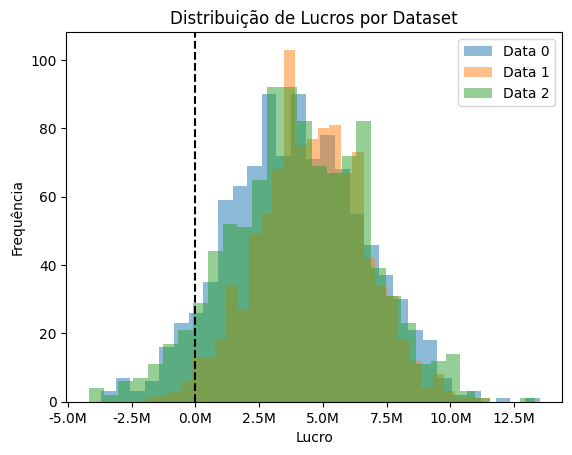

In [ ]:
grafico1 = boot0.plot(kind='hist', bins=30, alpha=0.5, label='Data0')
boot1.plot(kind='hist', bins=30, alpha=0.5, label='Data1', ax=grafico1)
boot2.plot(kind='hist', bins=30, alpha=0.5, label='Data2', ax=grafico1)
plt.legend(['Data 0', 'Data 1', 'Data 2']  )
plt.axvline(0, color='black', linestyle='--')
plt.xlabel('Lucro')
plt.ylabel('Frequência')
plt.title('Distribuição de Lucros por Dataset')
ax = plt.gca()
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.1f}M'))